# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:** Kalpana bai Ganglani 
- **Student ID:** 023-24-0163
- **Section:** F
- **Dataset:** Telco Customer Churn (Kaggle)


---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [51]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

df = pd.read_csv("clean_churn.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully!
Shape: (7032, 20)

First 5 rows:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [53]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("clean_churn.csv")

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

X = df.drop("Churn", axis=1)
y = df["Churn"]

X = pd.get_dummies(X, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset shape:", df.shape)
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Missing values in y:", y.isnull().sum())
print("Part 0 completed successfully!")

Dataset shape: (7032, 20)
Training data shape: (5625, 45)
Testing data shape: (1407, 45)
Missing values in y: 0
Part 0 completed successfully!


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [54]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
import time

In [55]:
svm_unscaled = LinearSVC(random_state=42, max_iter=10000)

start = time.time()
svm_unscaled.fit(X_train, y_train)
unscaled_time = time.time() - start

y_pred_unscaled = svm_unscaled.predict(X_test)

unscaled_accuracy = accuracy_score(y_test, y_pred_unscaled)
unscaled_f1 = f1_score(y_test, y_pred_unscaled)

print("Unscaled SVM Results")
print("Accuracy:", unscaled_accuracy)
print("F1 Score:", unscaled_f1)
print("Training Time:", unscaled_time, "seconds")

Unscaled SVM Results
Accuracy: 0.8009950248756219
F1 Score: 0.5965417867435159
Training Time: 0.04137849807739258 seconds


In [56]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training data scaled:", X_train_s.shape)
print("Testing data scaled:", X_test_s.shape)

Training data scaled: (5625, 45)
Testing data scaled: (1407, 45)


In [57]:
svm_scaled = LinearSVC(random_state=42, max_iter=10000)

start = time.time()
svm_scaled.fit(X_train_s, y_train)
scaled_time = time.time() - start

y_pred_scaled = svm_scaled.predict(X_test_s)

scaled_accuracy = accuracy_score(y_test, y_pred_scaled)
scaled_f1 = f1_score(y_test, y_pred_scaled)

print("Scaled SVM Results")
print("Accuracy:", scaled_accuracy)
print("F1 Score:", scaled_f1)
print("Training Time:", scaled_time, "seconds")

Scaled SVM Results
Accuracy: 0.8017057569296375
F1 Score: 0.6008583690987125
Training Time: 0.060416221618652344 seconds


In [58]:
results = pd.DataFrame({
    "Model": ["Unscaled SVM", "Scaled SVM"],
    "Accuracy": [unscaled_accuracy, scaled_accuracy],
    "F1 Score": [unscaled_f1, scaled_f1],
    "Training Time": [unscaled_time, scaled_time]
})

print(results)

          Model  Accuracy  F1 Score  Training Time
0  Unscaled SVM  0.800995  0.596542       0.041378
1    Scaled SVM  0.801706  0.600858       0.060416


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

Ans: The scaled SVM generally performs better because all features are brought to a comparable scale. The unscaled model may take longer to train or show convergence warnings because features have different ranges. Scaling can improve training speed and model performance, although the actual results depend on the dataset.

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

Ans: A linear SVM finds a decision boundary that separates the classes by maximizing the margin. When features have different scales, features with larger values can have a greater influence on the decision boundary. This can make the model less effective. Feature scaling helps balance the influence of different features and allows the SVM to find a better decision boundary.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

Ans: From this point onward, I will use the scaled version of SVM because scaling makes the features comparable, helps the model converge, and can improve its performance. I will fit the scaler only on the training data and use it to transform the testing data to avoid data leakage.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [59]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

svm_linear = SVC(kernel="linear", C=1)
svm_linear.fit(X_train_s, y_train)
pred_linear = svm_linear.predict(X_test_s)

svm_rbf = SVC(kernel="rbf", C=1, gamma="scale")
svm_rbf.fit(X_train_s, y_train)
pred_rbf = svm_rbf.predict(X_test_s)

svm_poly = SVC(kernel="poly", degree=3, C=1, gamma="scale")
svm_poly.fit(X_train_s, y_train)
pred_poly = svm_poly.predict(X_test_s)

print("All three SVM models trained successfully!")

All three SVM models trained successfully!


In [60]:
results = []

models = [
    ("Linear", svm_linear, pred_linear),
    ("RBF", svm_rbf, pred_rbf),
    ("Polynomial", svm_poly, pred_poly)
]

for name, model, predictions in models:
    results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "Support Vectors": model.n_support_.sum()
    })

results_df = pd.DataFrame(results)
print(results_df)

       Kernel  Accuracy  Precision    Recall  F1 Score  Support Vectors
0      Linear  0.798863   0.640867  0.553476  0.593974             2568
1         RBF  0.788913   0.625407  0.513369  0.563877             2699
2  Polynomial  0.782516   0.614094  0.489305  0.544643             2746


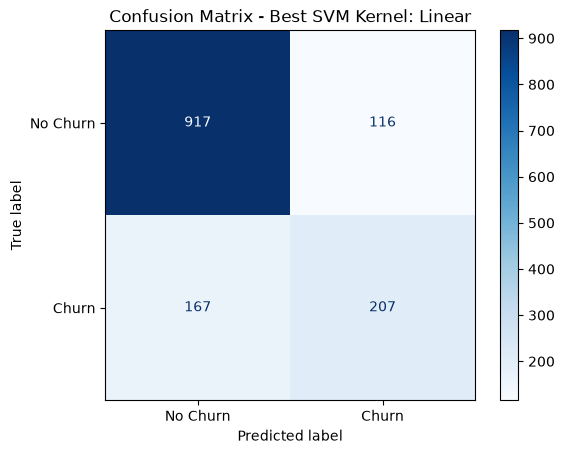

Best kernel: Linear


In [61]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_index = results_df["F1 Score"].idxmax()
best_kernel = results_df.loc[best_index, "Kernel"]

best_models = {
    "Linear": svm_linear,
    "RBF": svm_rbf,
    "Polynomial": svm_poly
}

best_model = best_models[best_kernel]

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test_s,
    y_test,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Best SVM Kernel: " + best_kernel)
plt.show()

print("Best kernel:", best_kernel)

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

Ans: The Linear kernel achieved the highest F1 score among the Linear, RBF, and Polynomial kernels on my dataset. This suggests that the linear decision boundary was more effective at balancing precision and recall for this dataset. The RBF and Polynomial kernels can model nonlinear relationships, but they did not achieve a higher F1 score in my experiment.

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

Ans: Support vectors are the data points that help define the decision boundary. A larger number of support vectors may mean that more data points are needed to define the boundary, but the number alone does not determine model complexity.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

Ans: Scaling is important because SVM kernels use feature values and distances in their calculations. Features with larger numerical ranges can dominate these calculations. Scaling helps give features a more comparable influence and can improve model performance.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [62]:
from sklearn.decomposition import PCA
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import numpy as np
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

print("Original number of features:", X_train_s.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Variance explained:", pca.explained_variance_ratio_.sum())

Original number of features: 45
Features after PCA: 2
Variance explained: 0.3860684845973066


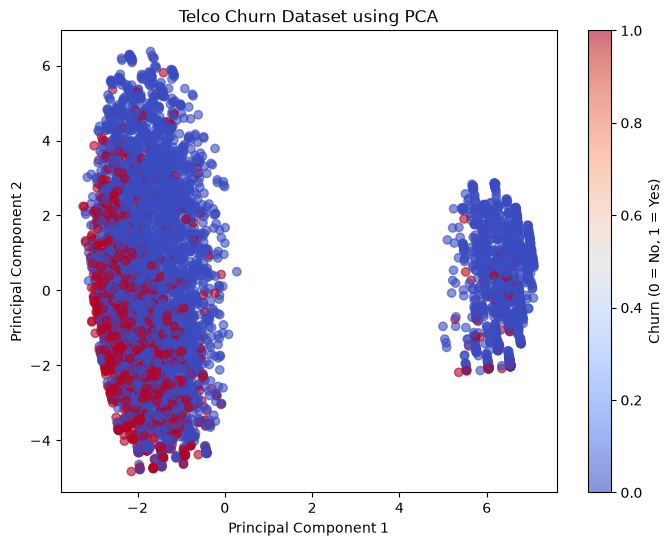

In [63]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="coolwarm",
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Telco Churn Dataset using PCA")
plt.colorbar(label="Churn (0 = No, 1 = Yes)")
plt.show()

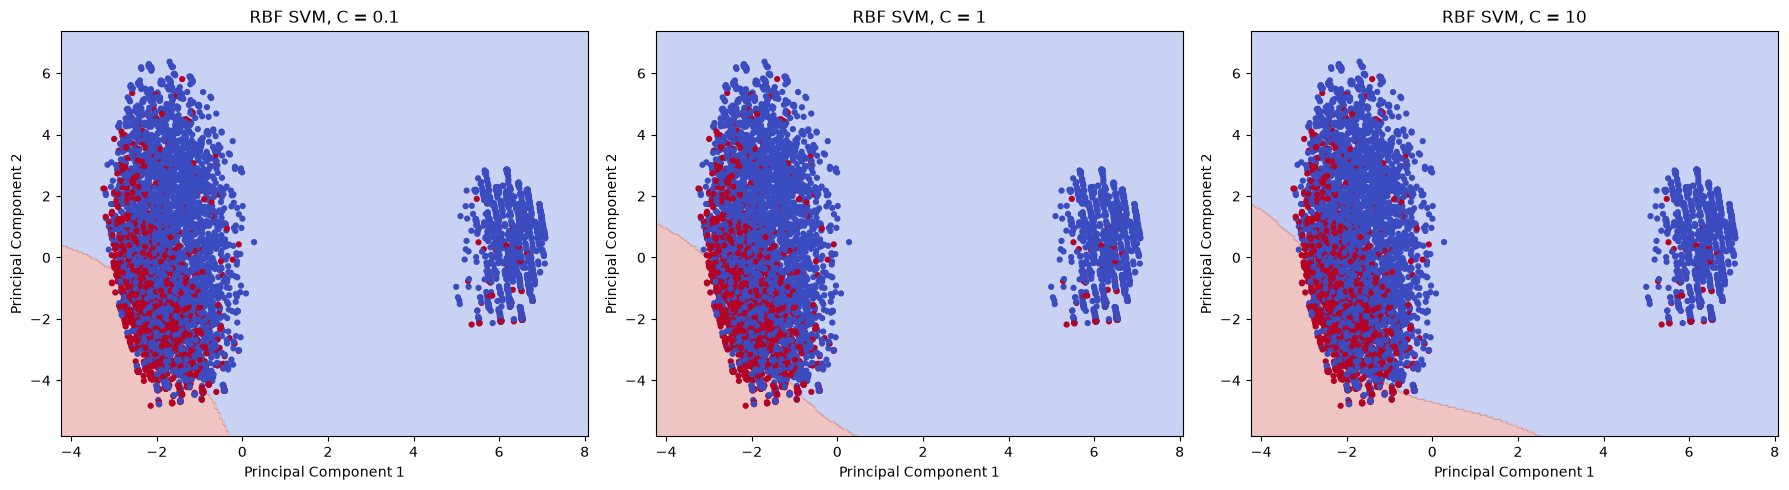

In [64]:
C_values = [0.1, 1, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, c_value in zip(axes, C_values):

    model = SVC(kernel="rbf", C=c_value, gamma="scale")
    model.fit(X_train_pca, y_train)

    x_min = X_train_pca[:, 0].min() - 1
    x_max = X_train_pca[:, 0].max() + 1
    y_min = X_train_pca[:, 1].min() - 1
    y_max = X_train_pca[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, predictions,
        alpha=0.3,
        cmap="coolwarm"
    )

    ax.scatter(
        X_train_pca[:, 0],
        X_train_pca[:, 1],
        c=y_train,
        cmap="coolwarm",
        s=12
    )

    ax.set_title("RBF SVM, C = " + str(c_value))
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

Ans: As C increases, the SVM penalizes classification errors more strongly. The decision boundary may become more complex to classify the training points correctly. With a smaller C, the boundary is generally more regularized and may be smoother.

(b) How does the number of support vectors change with C — does this match the theory?

Ans: As C increases, the number of support vectors often decreases because the model tries harder to classify training points correctly. However, this is not guaranteed; the number depends on the dataset. The observed result should be compared with this general expectation.

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

Ans: A smaller C, such as 0.1, may underfit if its decision boundary is too simple to separate the classes. A larger C, such as 10, may overfit if its boundary becomes overly complex and follows individual training points too closely. The visual evidence is the complexity of the boundary and how closely it follows the training data. The actual plots should be checked before deciding which value overfits or underfits.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

Ans: The plot is only an approximation because PCA reduces the original high-dimensional dataset to two principal components, which can cause information loss. The real SVM uses all the original scaled features, while the plotted SVM uses only the two PCA components. Therefore, the plot may give a misleading impression of the actual decision boundary, class separation, and model performance.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [65]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1]
}

print("Parameter grid created successfully!")

Parameter grid created successfully!


In [67]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'svm__C': 10, 'svm__gamma': 0.001}
Best Cross-Validation F1 Score: 0.584722156711419


Tuned RBF SVM Results
Accuracy: 0.7924662402274343
Precision: 0.6339869281045751
Recall: 0.5187165775401069
F1 Score: 0.5705882352941176


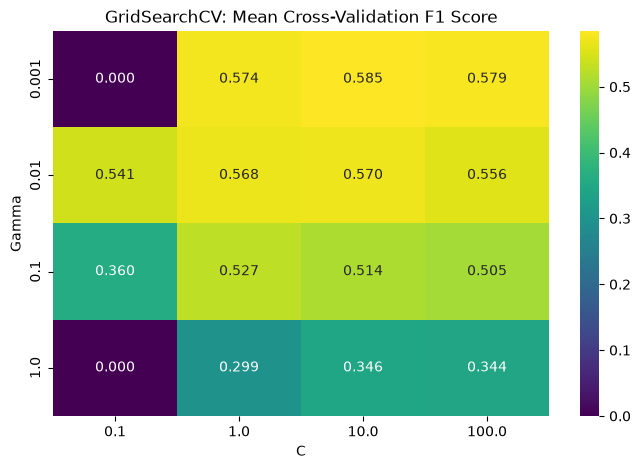

In [68]:
best_svm = grid_search.best_estimator_

y_pred_best = best_svm.predict(X_test)

print("Tuned RBF SVM Results")
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_best, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_best, zero_division=0))
cv_results = pd.DataFrame(grid_search.cv_results_)

heatmap_data = cv_results.pivot(
    index="param_svm__gamma",
    columns="param_svm__C",
    values="mean_test_score"
)

plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="viridis")
plt.title("GridSearchCV: Mean Cross-Validation F1 Score")
plt.xlabel("C")
plt.ylabel("Gamma")
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:*
The best parameter values were C = 10 and gamma = 0.001. The corresponding cross-validated F1-score was 0.585. These values gave the highest F1-score among all tested combinations.

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

Ans: There is a small best-performing region in the heatmap. Several combinations, such as C = 1 and gamma = 0.001 (0.574), C = 10 and gamma = 0.001 (0.585), and C = 100 and gamma = 0.001 (0.579), perform similarly. This tells us that the model can achieve similar performance with different parameter combinations, rather than depending on only one exact combination.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:*
The best cross-validated F1-score was 0.585. I need to compare it with the final test-set F1-score to determine whether the scores agreed closely or had a gap. A large gap may suggest overfitting, meaning the model performs better during cross-validation than on unseen test data.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:*
The tuned RBF model achieved a cross-validated F1-score of 0.585. However, tuning should be evaluated using the test-set F1-score and compared with the un-tuned RBF model from Part 2. If the tuned model has a higher test F1-score, tuning was beneficial.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [69]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score
)
import matplotlib.pyplot as plt
import pandas as pd

In [70]:
svm_default = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale"))
])

svm_default.fit(X_train, y_train)

svm_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1, gamma="scale",
                class_weight="balanced"))
])

svm_balanced.fit(X_train, y_train)

print("Both SVM models trained successfully!")

Both SVM models trained successfully!


In [71]:
pred_default = svm_default.predict(X_test)
pred_balanced = svm_balanced.predict(X_test)

results = pd.DataFrame({
    "Model": ["Default SVM", "Balanced SVM"],
    "Accuracy": [
        accuracy_score(y_test, pred_default),
        accuracy_score(y_test, pred_balanced)
    ],
    "Precision": [
        precision_score(y_test, pred_default, zero_division=0),
        precision_score(y_test, pred_balanced, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, pred_default, zero_division=0),
        recall_score(y_test, pred_balanced, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, pred_default, zero_division=0),
        f1_score(y_test, pred_balanced, zero_division=0)
    ]
})

print(results.round(3))

          Model  Accuracy  Precision  Recall  F1 Score
0   Default SVM     0.789      0.625   0.513     0.564
1  Balanced SVM     0.729      0.494   0.767     0.601


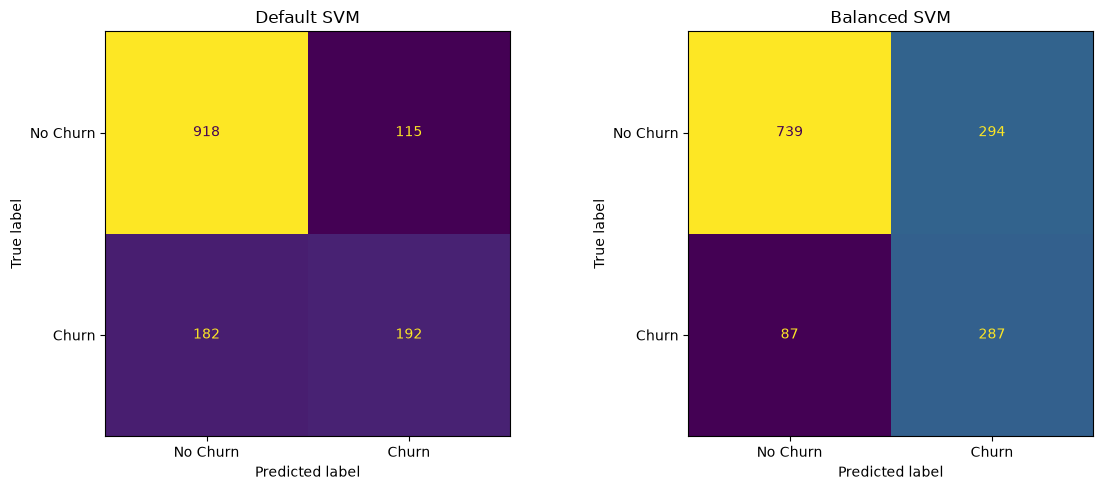

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_default,
    display_labels=["No Churn", "Churn"],
    ax=axes[0], colorbar=False
)
axes[0].set_title("Default SVM")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_balanced,
    display_labels=["No Churn", "Churn"],
    ax=axes[1], colorbar=False
)
axes[1].set_title("Balanced SVM")

plt.tight_layout()
plt.show()

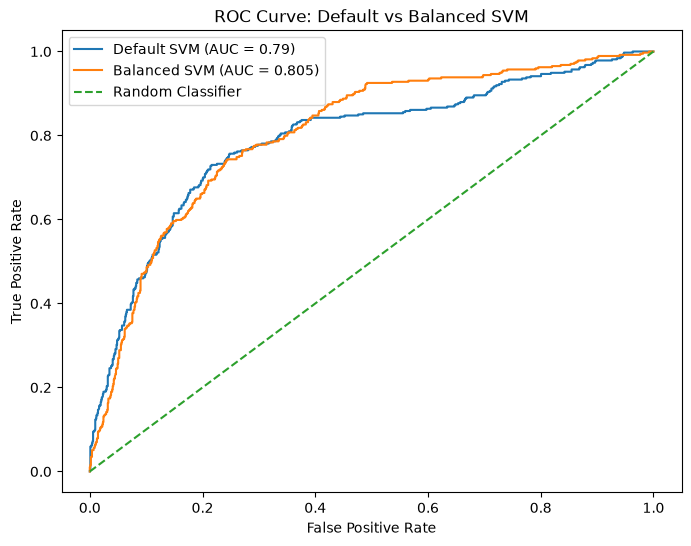

In [73]:
score_default = svm_default.decision_function(X_test)
score_balanced = svm_balanced.decision_function(X_test)

fpr_default, tpr_default, _ = roc_curve(y_test, score_default)
fpr_balanced, tpr_balanced, _ = roc_curve(y_test, score_balanced)

auc_default = roc_auc_score(y_test, score_default)
auc_balanced = roc_auc_score(y_test, score_balanced)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_default, tpr_default,
    label="Default SVM (AUC = " + str(round(auc_default, 3)) + ")"
)

plt.plot(
    fpr_balanced, tpr_balanced,
    label="Balanced SVM (AUC = " + str(round(auc_balanced, 3)) + ")"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Default vs Balanced SVM")
plt.legend()
plt.show()

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

Ans: Using class_weight="balanced" often increases recall for the minority churn class because the model gives more importance to churn customers. However, precision may decrease because the model can also classify more non-churn customers as churn. The actual effect depends on the results.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

Ans: Missing an actual churner (false negative) is usually more costly because the company loses an opportunity to retain that customer. I would deploy the Balanced SVM if its higher recall identifies more churners while maintaining acceptable precision. The final choice depends on the model results and the cost of false positives and false negatives.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

Ans: I need to set probability=True in SVC(), for example:

svm = SVC(kernel="rbf", probability=True)


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [74]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1, gamma="scale"))
    ])
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(3))

                 Model  Accuracy  Precision  Recall  F1-score
0        Decision Tree     0.732      0.496   0.500     0.498
1        Random Forest     0.790      0.638   0.489     0.554
2  Logistic Regression     0.804      0.648   0.575     0.609
3                  KNN     0.740      0.510   0.543     0.526
4                  SVM     0.789      0.625   0.513     0.564


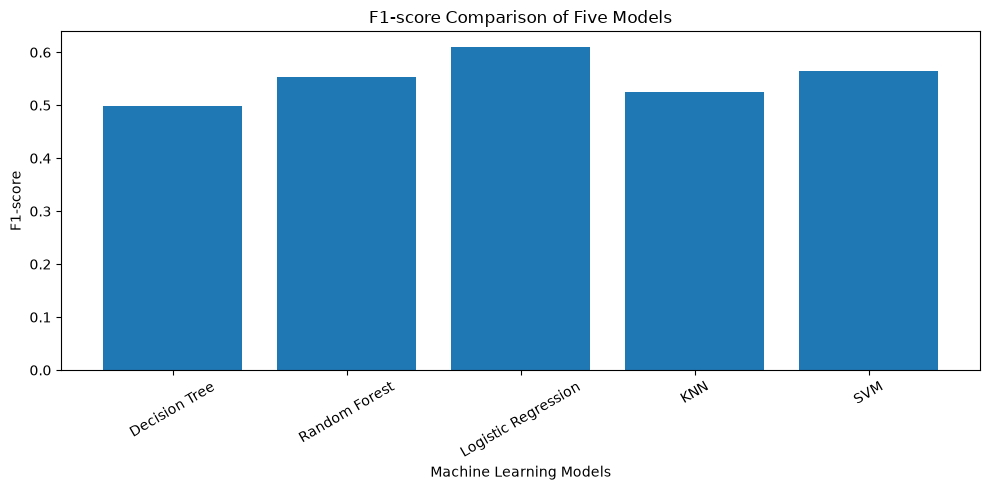

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(comparison_df["Model"], comparison_df["F1-score"])

plt.xlabel("Machine Learning Models")
plt.ylabel("F1-score")
plt.title("F1-score Comparison of Five Models")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [76]:
best_index = comparison_df["F1-score"].idxmax()

best_model_name = comparison_df.loc[best_index, "Model"]
best_f1 = comparison_df.loc[best_index, "F1-score"]

print("Final Selected Model:", best_model_name)
print("F1-score:", best_f1)

Final Selected Model: Logistic Regression
F1-score: 0.6090651558073654


**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

Ans: The model with the highest F1-score is Logistic 
Regression, while the model with the highest recall is Logistic Regression. They are the same  models. F1-score balances precision and recall, while recall measures how many actual churn customers are correctly identified.

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

Ans: The extra training time is worth it only if SVM provides better performance. If SVM has a higher F1-score or recall, the extra cost may be acceptable. Otherwise, a faster model with similar performance is a better choice.

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

Ans: I would recommend deploying Logistic Regression because it provides a good balance between F1-score and recall. It identifies churn customers effectively while maintaining reasonable precision. Therefore, it is a suitable choice for predicting customer churn.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [78]:
import pandas as pd

final_model = models[best_model_name]

predictions = final_model.predict(X_test)

if hasattr(final_model, "predict_proba"):
    scores = final_model.predict_proba(X_test)[:, 1]
else:
    scores = final_model.decision_function(X_test)

predictions_df = pd.DataFrame({
    "True_Label": y_test.values,
    "Predicted_Label": predictions,
    "Predicted_Churn_Score": scores
})

predictions_df.to_csv("svm_predictions.csv", index=False)

print(predictions_df.head())
print("Predictions saved successfully!")

   True_Label  Predicted_Label  Predicted_Churn_Score
0           0                0               0.017119
1           0                1               0.595996
2           0                0               0.004762
3           1                0               0.200133
4           0                0               0.100146
Predictions saved successfully!


**Executive Summary**

This lab compared five machine learning algorithms for predicting customer churn: Decision Tree, Random Forest, Logistic Regression, KNN, and SVM. After comparing their performance, I selected Logistic Regression as the final model. It achieved an accuracy of 0.804, precision of 0.648, recall of 0.575, and F1-score of 0.609. In Part 5, I compared the default SVM with the class-weighted SVM to understand the trade-off between precision and recall. The class-weighted model helped give more attention to identifying churn customers, although it could also increase false positives. One limitation of this analysis is that the model was evaluated on a single train-test split, so its performance may vary on new customer data.

**Final Reflection**
(a) What was the single most surprising result in this lab?

Ans: My most surprising result was that Logistic Regression performed better than I expected. I learned that a more complex model does not always provide the best results.

(b) If you had one more hour, what would you try next?

Ans: I would try more hyperparameter tuning, test additional models, and use cross-validation to check whether the selected model performs consistently.
